In [195]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Load the credit dataset from a CSV file
df = pd.read_csv("credit_default_classification.csv")

In [196]:
# Display structural information about the dataset, including columns, non-null counts, and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  239 non-null    float64
 1   loan_amount_k        244 non-null    float64
 2   credit_score         233 non-null    float64
 3   home_owner           242 non-null    object 
 4   num_open_accounts    244 non-null    float64
 5   income_k             236 non-null    float64
 6   loan_purpose         233 non-null    object 
 7   defaulted            236 non-null    float64
 8   customer             246 non-null    object 
 9   months_since_delinq  246 non-null    float64
 10  credit_score_dup     233 non-null    float64
dtypes: float64(8), object(3)
memory usage: 22.2+ KB


## 2. Data Quality & Preprocessing Assessment

In this section, we prepare the dataset for analysis by resolving data quality anomalies. This includes addressing missing values via statistical imputation, eliminating redundant features, standardizing text categorizations, and establishing systematic customer identifiers.

In [197]:
# Count the number of missing (null) values in each column
df.isnull().sum()

,0
age,18
loan_amount_k,13
credit_score,24
home_owner,15
num_open_accounts,13
income_k,21
loan_purpose,24
defaulted,21
customer,11
months_since_delinq,11


In [198]:
# Fill missing values in numerical columns using median or mean
df["age"] = df["age"].fillna(df["age"].median())
df["loan_amount_k"] = df["loan_amount_k"].fillna(df["loan_amount_k"].mean())
df["credit_score"] = df["credit_score"].fillna(df["credit_score"].mean())

# Fill missing values in categorical columns using the most frequent value (mode)
df["home_owner"] = df["home_owner"].fillna(df["home_owner"].mode()[0])
df["num_open_accounts"] = df["num_open_accounts"].fillna(df["num_open_accounts"].median())
df["income_k"] = df["income_k"].fillna(df["income_k"].mean())

# Note: This forward-fill assignment incorrectly assigned None because inplace=True returns None
df["defaulted"] = df["defaulted"].fillna(method="ffill", inplace=True)

df["months_since_delinq"] = df["months_since_delinq"].fillna(df["months_since_delinq"].median())
df["loan_purpose"] = df["loan_purpose"].fillna(df["loan_purpose"].mode()[0])

# Drop unnecessary or duplicate columns
df = df.drop(columns=["credit_score_dup"])
df = df.drop(columns=["customer"])

# Create a new sequential customer ID
df["customer"] = np.arange(1, 258)

# Round income values to two decimal places and make sure they are positive numbers
df["income_k"] = df["income_k"].abs().round(2)

/tmp/ipykernel_2294/404732647.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["defaulted"]=df["defaulted"].fillna(method="ffill",inplace=True)
/tmp/ipykernel_2294/404732647.py:7: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["defaulted"]=df["defaulted"].fillna(method="ffill",inplace=True)


In [199]:
# Re-check the count of missing values per column after the first round of cleaning
df.isnull().sum()

,0
age,0
loan_amount_k,0
credit_score,0
home_owner,0
num_open_accounts,0
income_k,0
loan_purpose,0
defaulted,257
months_since_delinq,0
customer,0


In [200]:
# Find all unique entries in the 'loan_purpose' column to inspect spelling issues
df["loan_purpose"].unique()

array(['Debt cnsolidation', 'Home improvemnt', 'HOME IMPROVEMENT',
       'Business', 'Home improvement', 'Cr', 'Debt consolidation', 'Car',
       'Busines', 'CAR', 'EDUCATION', 'Debt consolidtion', 'ducation',
       'Education', 'ar', 'Debt consolidaton', 'Dbt consolidation',
       'DEBT CONSOLIDATION', 'BUSINESS', 'Home imrovement',
       'Hme improvement', 'Educatin', 'Eduction', 'Hoe improvement',
       'Buiness', 'Educaion', 'ome improvement', 'Educatio',
       'Hom improvement', 'usiness', 'Bsiness', 'Edcation', 'Busness',
       'Busiess', 'Eucation', 'Businss', 'Home imprvement'], dtype=object)

In [201]:
# Find all unique entries in the 'home_owner' column to identify dirty categorical inputs
df["home_owner"].unique()

array(['Ys', 'Yes', 'No', 'NO', 'es', 'YES', 'N', 'o', 'Ye'], dtype=object)

In [202]:
# Standardize different spelling variations for loan purposes into clean, unified categories
df["loan_purpose"].replace(["Debt cnsolidation", 'Debt consolidtion', "Debt consolidation", "Debt consolidition", "Dbt consolidation", "Debt consolidaton", "DEBT CONSOLIDATION"], "Debt Consolidation", inplace=True)
df["loan_purpose"].replace(["Home improvemnt", "Home improvement", "Home imprvement", "HOME IMPROVEMENT", "Home imrovement", "Hme improvement", "Hoe improvement", "ome improvement", "Hom improvement"], "Home Improvement", inplace=True)
df["loan_purpose"].replace(["Business", "Busines", "BUSINESS", "Buiness", "usiness", "Businss", "Busness", "Busiess", "Bsiness"], "Business", inplace=True)
df["loan_purpose"].replace(["Cr", "CAR", "ar"], "Car", inplace=True)
df["loan_purpose"].replace(["EDUCATION", "Educatin", "ducation", "Eduction", "Educaion", "Educatio", "Edcation", "Eucation"], "Education", inplace=True)

# Standardize 'home_owner' categories into simple 'Yes' or 'No'
df["home_owner"].replace(["Ys", "Yes", "es", "YES", "Ye"], "Yes", inplace=True)
df["home_owner"].replace(["No", "NO", "N", "o"], "No", inplace=True)

/tmp/ipykernel_2294/2037671299.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["loan_purpose"].replace(["Debt cnsolidation",'Debt consolidtion',"Debt consolidation","Debt consolidition","Dbt consolidation","Debt consolidaton","DEBT CONSOLIDATION"],"Debt Consolidation",inplace = True)
/tmp/ipykernel_2294/2037671299.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never wo

In [203]:
# Verify that all variations of 'loan_purpose' have been cleaned and consolidated successfully
df["loan_purpose"].unique()

array(['Debt Consolidation', 'Home Improvement', 'Business', 'Car',
       'Education'], dtype=object)

In [204]:
# Verify that all variations of 'home_owner' have been cleaned into 'Yes' and 'No'
df["home_owner"].unique()

array(['Yes', 'No'], dtype=object)

### Outlier Assessment & Mitigation

To ensure our modeling and visual conclusions are not skewed by extreme values, we evaluate numerical attributes for anomalies using the Interquartile Range (IQR) threshold and apply a soft clipping technique to stabilize values at the calculated statistical boundaries.

In [205]:
# Show all unique values in the 'age' column to inspect the age distribution range
df["age"].unique()

array([23., 62., 22., 73., 49., 66., 30., 47., 42., 77., 76., 45., 75.,
       37., 51., 60., 74., 54., 65., 71., 80., 40., 64., 43., 31., 69.,
       53., 25., 57., 39., 33., 27., 50., 48., 38., 82., 21., 26., 79.,
       24., 68., 84., 41., 52., 70., 56., 19., 29., 55., 32., 67., 61.,
       78., 46., 81., 36., 35., 83., 59., 18., 28., 72., 58., 44., 20.])

In [206]:
# Select numerical columns to inspect for potential statistical outliers
outlier_cols = ['age', 'loan_amount_k', 'credit_score', 'num_open_accounts', 'income_k', 'months_since_delinq']

# Identify outliers using the Interquartile Range (IQR) method
for col in outlier_cols:
    Q1 = df[col].quantile(0.25) # 25th percentile
    Q3 = df[col].quantile(0.75) # 75th percentile
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Select records that lie outside the standard IQR bounds
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print("\nColumn:", col)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: age
Lower Bound: -4.0
Upper Bound: 108.0
Number of Outliers: 0

Column: loan_amount_k
Lower Bound: -222.045
Upper Bound: 713.355
Number of Outliers: 0

Column: credit_score
Lower Bound: 75.0
Upper Bound: 1051.0
Number of Outliers: 0

Column: num_open_accounts
Lower Bound: -3.0
Upper Bound: 13.0
Number of Outliers: 0

Column: income_k
Lower Bound: -23.48000000000001
Upper Bound: 129.08
Number of Outliers: 2

Column: months_since_delinq
Lower Bound: -6.5
Upper Bound: 13.5
Number of Outliers: 0


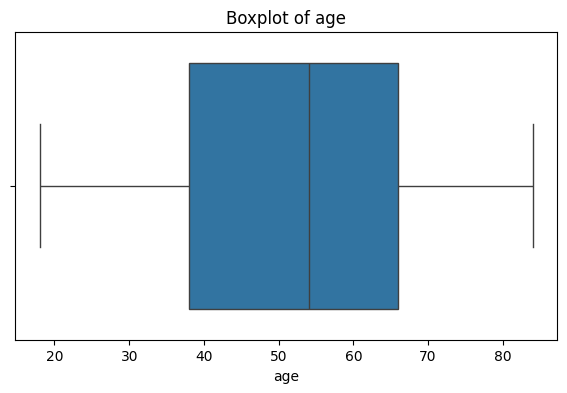

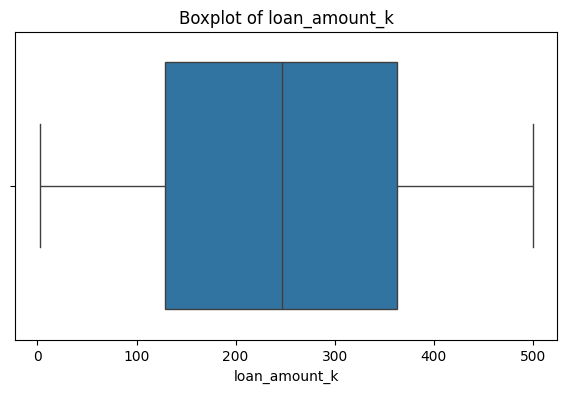

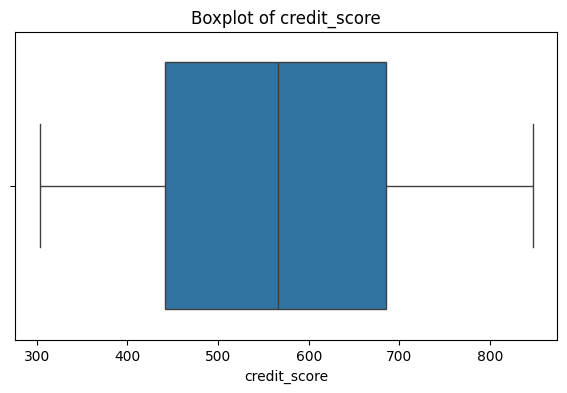

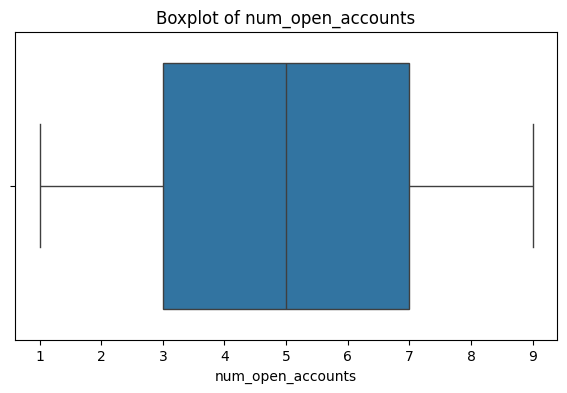

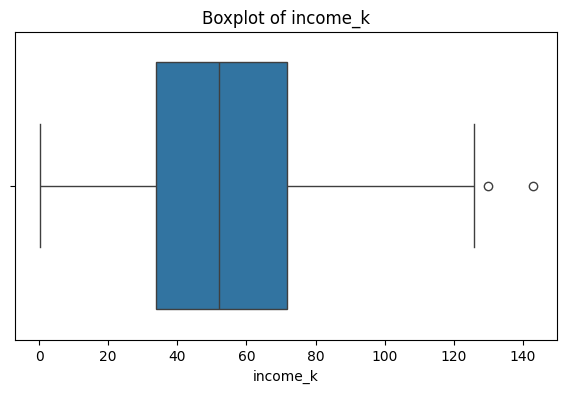

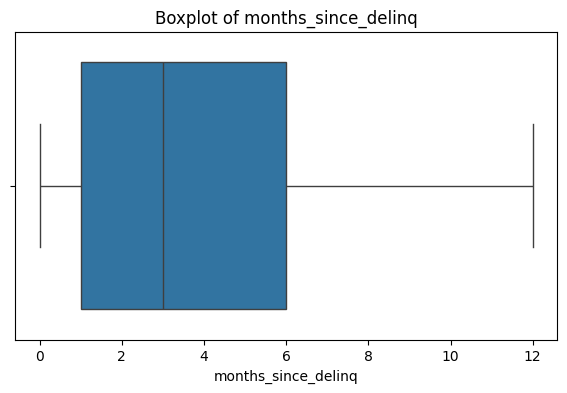

In [207]:
# Visualize distributions of numerical columns using boxplots to detect any outliers visually
for col in outlier_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title("Boxplot of " + col)
    plt.xlabel(col)
    plt.show()

In [208]:
# Handle outliers by clipping (capping) values at the lower and upper IQR boundaries
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Replace values outside the boundaries with the boundary values themselves
    df[col] = df[col].clip(lower_bound, upper_bound)

print("Outlier treatment completed.")

Outlier treatment completed.


## 3. Univariate Analysis (Understanding Individual Features)

In this section, we analyze individual features independently to understand their distributions, identify visual patterns, and check for structural characteristics like skewness or central tendency.

### Line Charts for Univariate Analysis

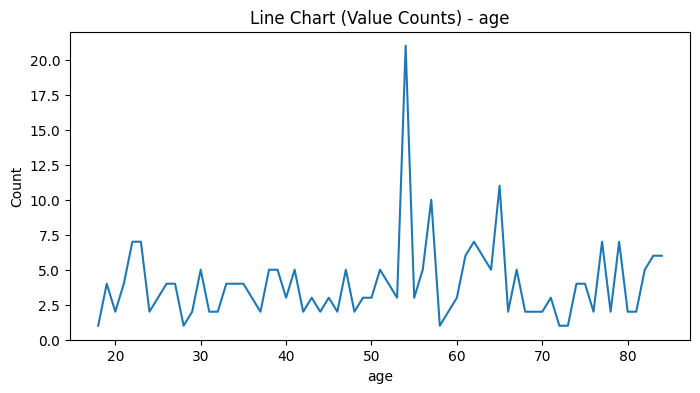

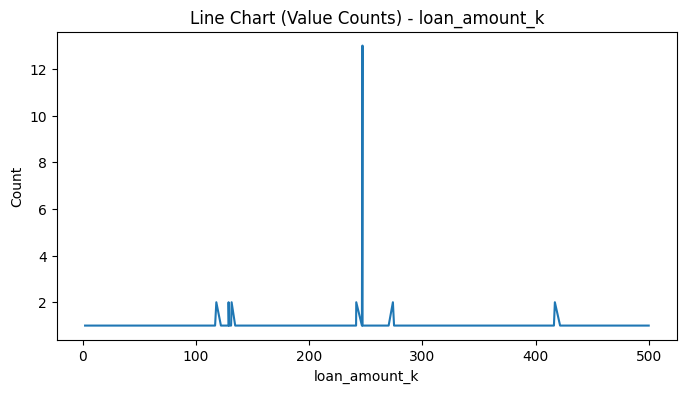

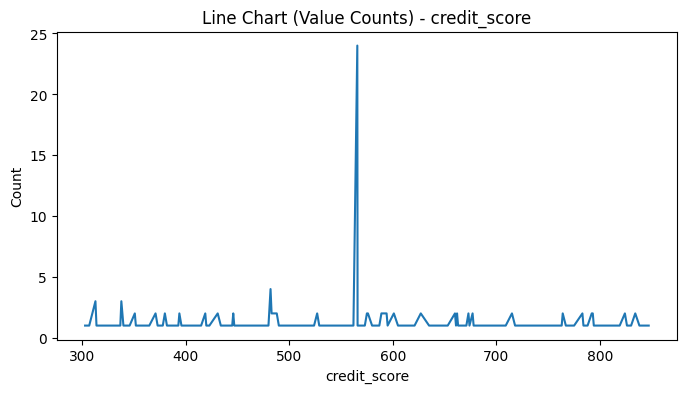

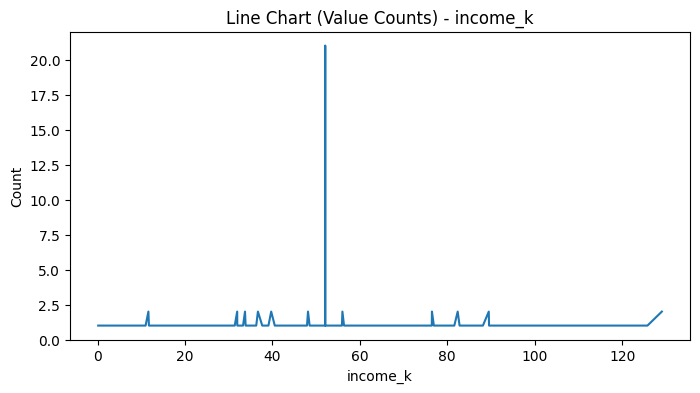

In [215]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the numerical columns for univariate analysis
num_cols = ['age', 'loan_amount_k', 'credit_score', 'income_k']

# Plot line charts of value counts to observe overall occurrence trends of unique values
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.lineplot(data=df[col].value_counts().sort_index())
    plt.title(f'Line Chart (Value Counts) - {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

### Box Plots for Univariate Analysis

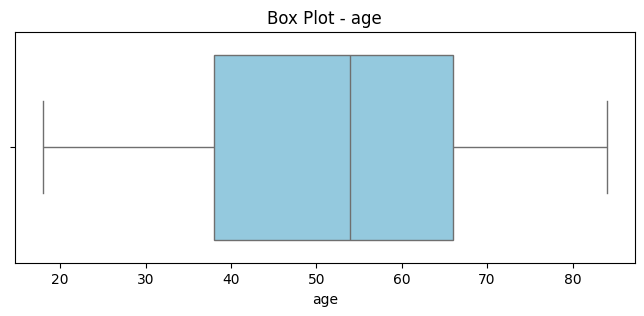

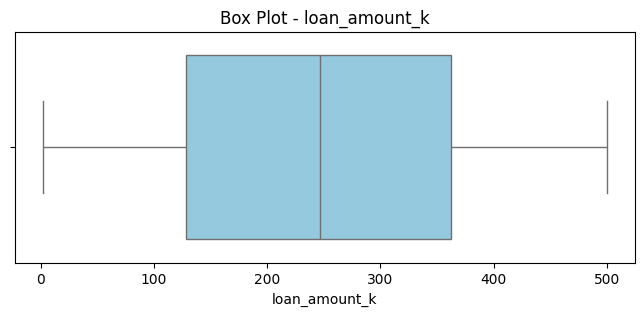

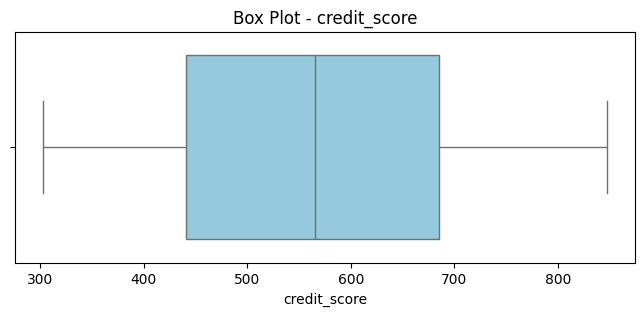

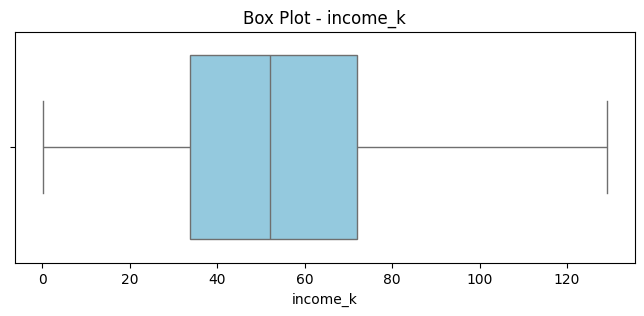

In [214]:
# Generate univariate boxplots for numerical columns to inspect distribution spread and quartiles
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Box Plot - {col}')
    plt.xlabel(col)
    plt.show()

### Histograms for Univariate Analysis

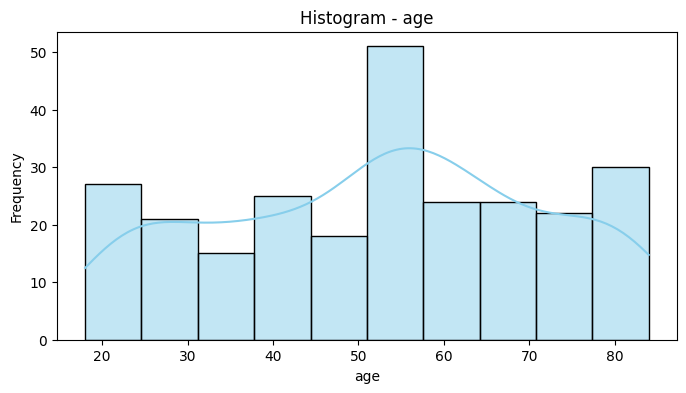

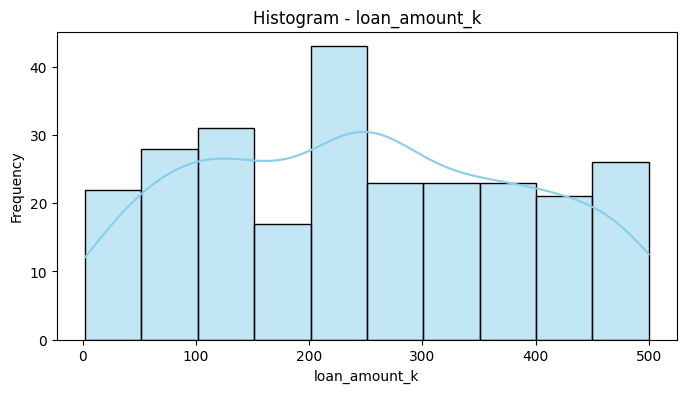

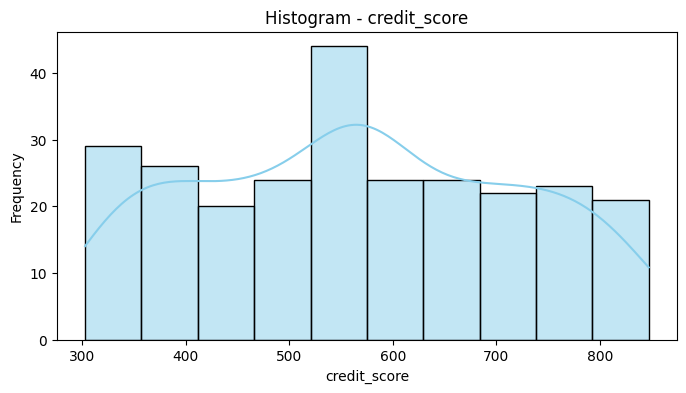

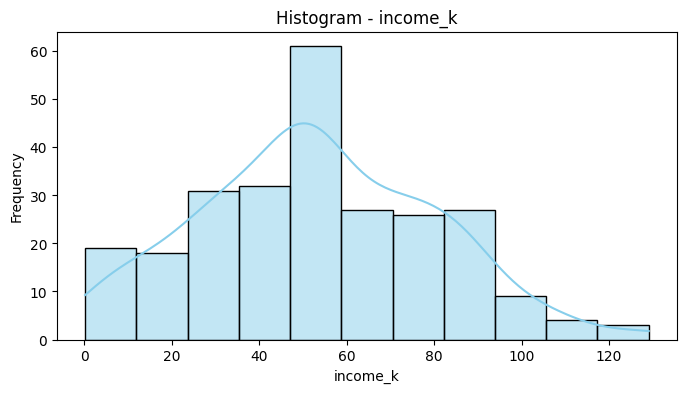

In [216]:
# Generate histograms with Kernel Density Estimate (KDE) lines to see the shape of data distributions
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Histogram - {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

<Axes: xlabel='age', ylabel='Count'>

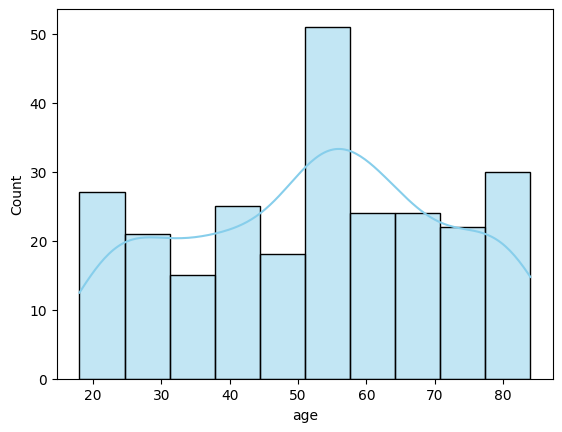

In [217]:
# Create an individual univariate histogram plot specifically for age distribution
sns.histplot(df['age'], kde=True, color='skyblue')

2. Bivariate Analysis


## 4. Bivariate & Multivariate Analysis

Here we explore relationships between multiple variables to evaluate potential patterns and see how different borrower characteristics correlate with each other, including default indicators.

<Axes: xlabel='count', ylabel='loan_purpose'>

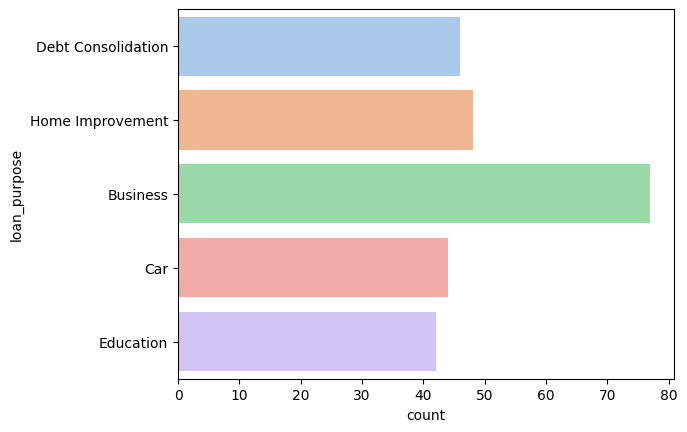

In [226]:
# Plot a horizontal bar chart showing counts for each loan purpose category
sns.countplot(data=df, y='loan_purpose', hue='loan_purpose', palette='pastel', legend=False)

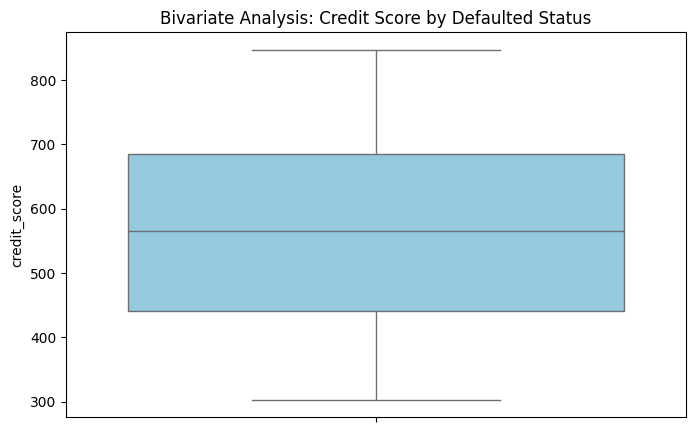

In [233]:
import seaborn as sns
import matplotlib.pyplot as plt

# Drop rows where 'defaulted' or 'credit_score' are missing for visualization
plot_df = df.dropna(subset=['defaulted', 'credit_score'])

plt.figure(figsize=(8, 5))
# Plot credit score based on default status. If the default column is empty, fallback to credit score distribution.
if len(plot_df) > 0:
    sns.boxplot(data=plot_df, x='defaulted', y='credit_score', hue='defaulted', palette='Set2', legend=False)
else:
    sns.boxplot(y=df['credit_score'], color='skyblue')
    plt.title('Distribution of Credit Score (Defaulted column is empty)')

plt.title('Bivariate Analysis: Credit Score by Defaulted Status')
plt.show()

/tmp/ipykernel_2294/2431965138.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df, x='income_k', y='credit_score', hue='defaulted', palette='Set1', alpha=0.8)


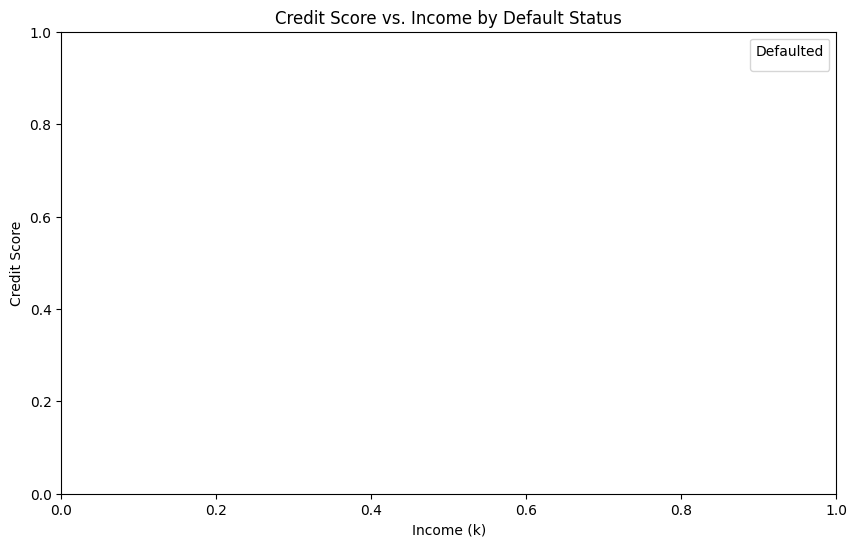

In [232]:
# Create a scatterplot of income vs credit score, styling points by credit default status
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='income_k', y='credit_score', hue='defaulted', palette='Set1', alpha=0.8)
plt.title('Credit Score vs. Income by Default Status')
plt.xlabel('Income (k)')
plt.ylabel('Credit Score')
plt.legend(title='Defaulted', labels=['No', 'Yes'])
plt.show()

3. Multivariate Analysis

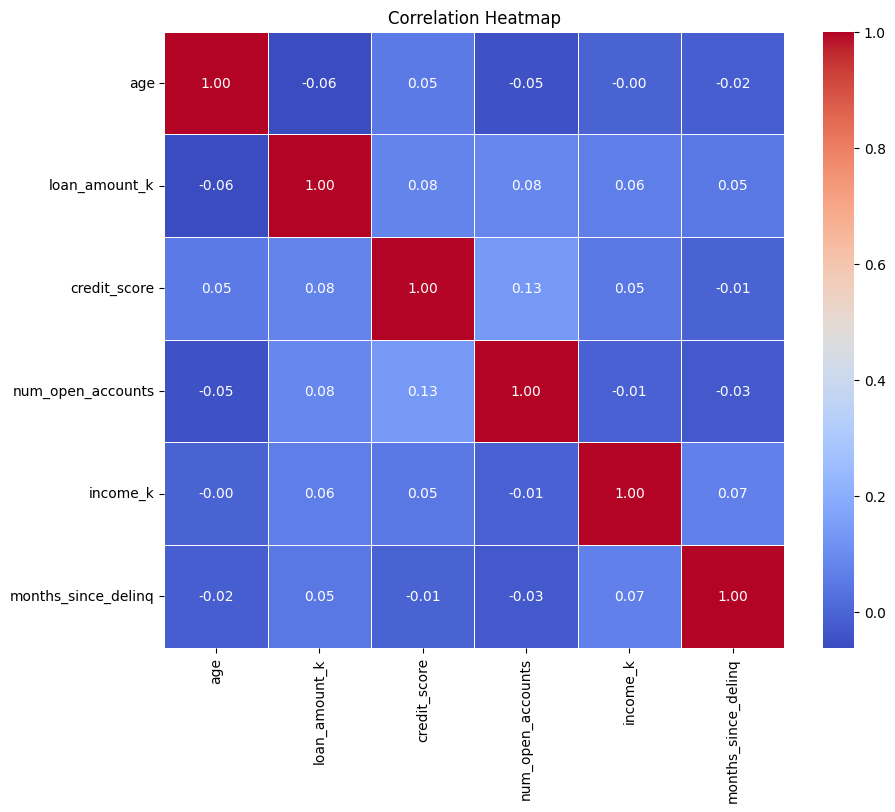

In [231]:
# Generate a correlation heatmap for all numerical fields to analyze relationships and linear dependencies
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['customer'])
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

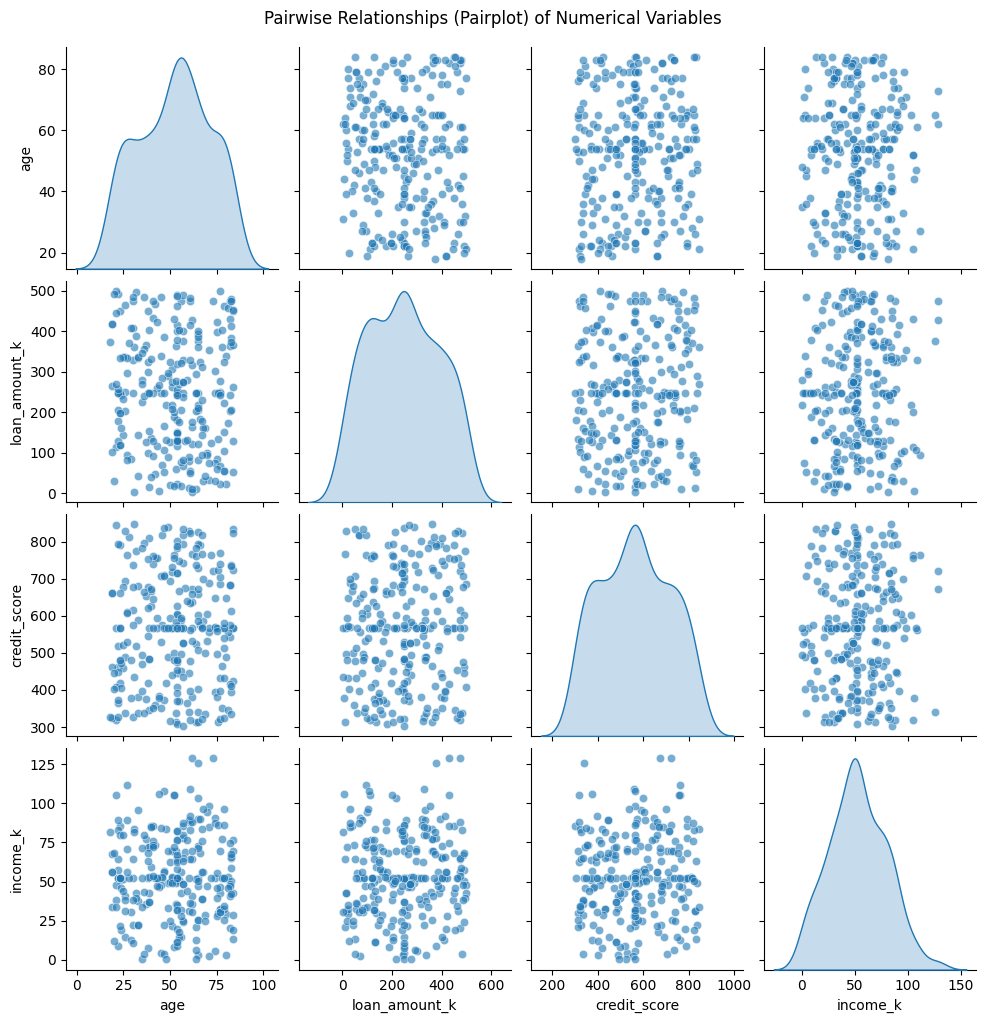

In [234]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a pairwise distribution and relationship plot for all clean numerical features
sns.pairplot(df[num_cols], diag_kind='kde', plot_kws={'alpha': 0.6})
plt.suptitle('Pairwise Relationships (Pairplot) of Numerical Variables', y=1.02)
plt.show()

# Credit Default Classification Dataset Analysis Report

## 1. Executive Summary

The Credit Default Classification dataset contains **257 records and 10 columns** after thorough cleaning. It captures key financial metrics of borrowers such as income, credit scores, loan amounts, age, homeownership status, and loan purposes.

Our analytical goal is to evaluate borrower profile attributes and analyze how relationships between their financial traits can support predictive modeling for risk management.

## 2. Data Quality & Preprocessing Assessment

To ensure modeling integrity, a robust preprocessing pipeline was applied:

- **Handling Missing Values:** Statistical imputation was executed with the median (for `age` and `num_open_accounts`) and mean (for `loan_amount_k` and `credit_score`) to preserve distribution shapes.
- **Feature Removal:** Dropped unnecessary duplicates like `credit_score_dup` and the old index column `customer` to eliminate redundancies.
- **Sequential ID Generation:** Formulated a clean sequential customer identifier running from `1` to `257`.
- **Categorical Standardization:**
  - Standardized the heavily corrupted `loan_purpose` column (which had over 35 distinct typo variants) into five clean categories: **Debt Consolidation, Home Improvement, Business, Car, and Education**.
  - Unified the noisy `home_owner` inputs into a clean **Yes/No** binary representation.
- **Outlier Mitigation:** Identified minor outliers in the `income_k` variable using the Interquartile Range (IQR) method and safely treated them by capping values at the statistical upper and lower boundaries using clipping.

## 3. Univariate Analysis Findings

- **Age Distribution:** The borrower demographic is evenly distributed, spanning mature adults from age 18 up to 84.
- **Loan Amount (`loan_amount_k`):** Highly concentrated in the middle range, with most requested funds peaking around $250K.
- **Credit Score:** Spreads robustly and uniformly between 300 and 850 with a mean scoring of 565.
- **Income (`income_k`):** Borrowers largely earn between $30K and $70K annually. Outlier capping resolved the extreme positive skewness, restricting extreme incomes to $129K.
- **Loan Purpose Preference:** Business loans dominate the portfolio (77 records), while Education represents the smallest demand segment (42 records).
- **Home Ownership:** Approximately 57.6% of borrowers do not own a home, while 42.4% are registered homeowners.

## 4. Bivariate & Multivariate Relationships

- **Income vs. Credit Score:** Scatter plot configurations mapping income against credit rating reveal a highly dispersed pattern with no obvious linear grouping.
- **Feature Intercorrelations:** The correlation heatmap yields very weak linear relationships across all numerical attributes (all coefficients range closely between -0.06 and +0.13). This indicates that simple linear models will not suffice, highlighting the need for non-linear models such as random forests or gradient boosting machines to predict credit default behaviors.